In [10]:
import pandas as pd

df = pd.read_csv("/home/thinkpad/Documents/BrototypeStudying/paper_three/Module12/data/customer_segmentation.csv")

In [11]:
data = df.drop(columns="customer_id")

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X = scaler.fit_transform(data)

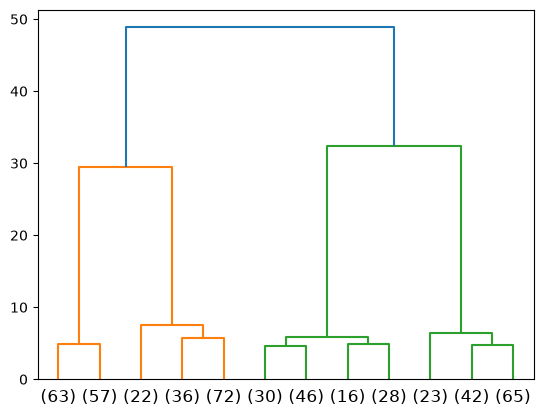

In [13]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

Z = linkage(X, method="ward")
dendrogram(Z, truncate_mode="lastp", p=12)
plt.show()


Text(0, 0.5, 'inertia')

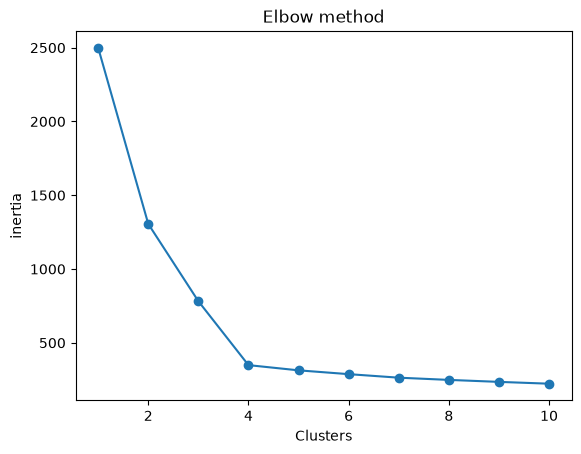

In [14]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X)
    inertia.append(model.inertia_)
    
plt.plot(range(1, 11), inertia, marker = "o")
plt.title("Elbow method")
plt.xlabel("Clusters")
plt.ylabel("inertia")

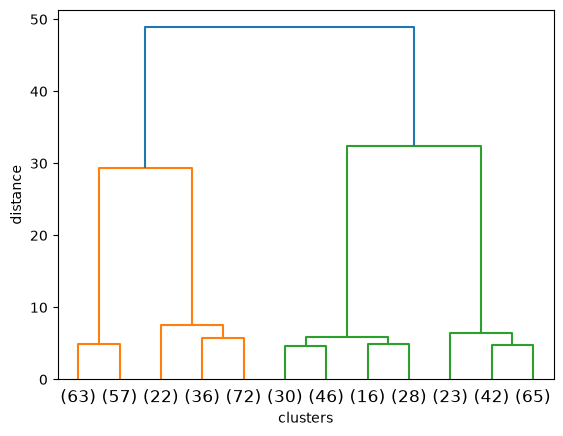

In [23]:
from scipy.cluster.hierarchy import dendrogram,linkage

Z = linkage(X, method="ward")
dendrogram(Z, truncate_mode="lastp", p=12)
plt.xlabel("clusters")
plt.ylabel("distance")
plt.show()

In [16]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

model = AgglomerativeClustering(n_clusters=4)

model.fit(X)

data["cluster"] = model.labels_

print(silhouette_score(X, model.labels_))

0.6073112039686982


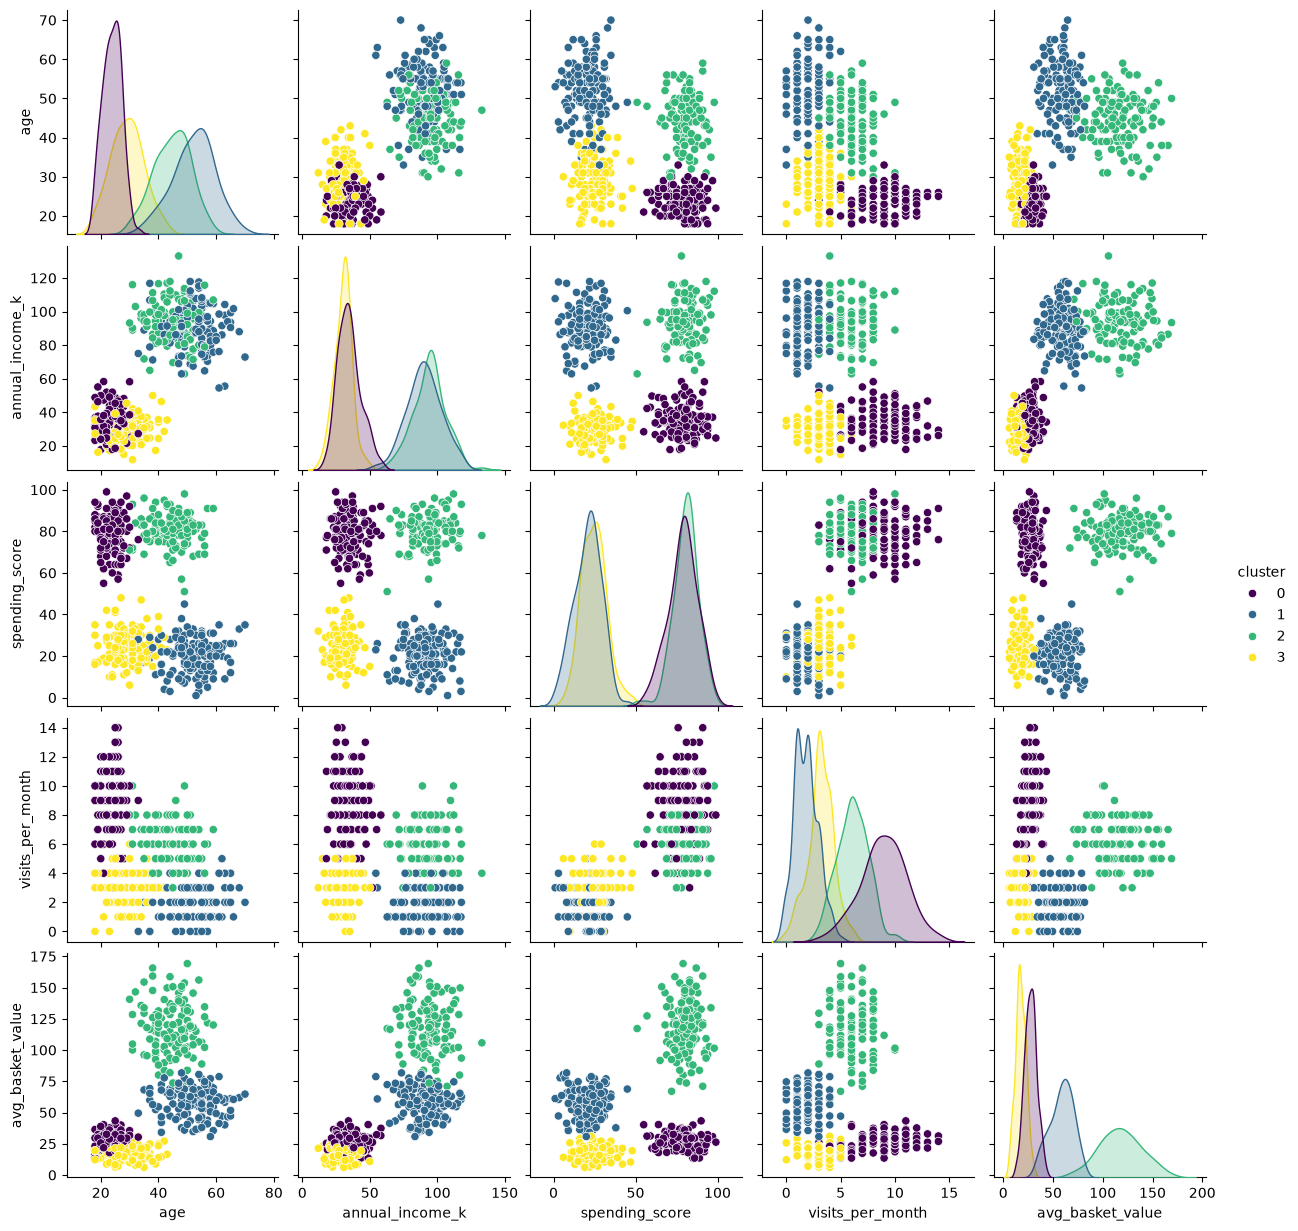

In [17]:
import seaborn as sns

sns.pairplot(data, hue="cluster", palette="viridis")